# Member 3 — MMM Model Evaluation, Testing & Integration

**Goal:** independently audit Member 2's four saved regressors, select using *existing expanding time-series cross-validation*, evaluate the held-out period and demonstrate deployment-safe budget prediction. This notebook **does not refit on test data**.

Outputs are saved to `models/`, `outputs/mmm/` and `reports/` in the original project.

In [1]:
from pathlib import Path
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from IPython.display import display, Image, Markdown

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p/'data/processed/mmm_features.csv').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start Jupyter within the cloned project directory.')
sys.path.insert(0, str(PROJECT_ROOT))
from src.predict_sales import (load_model, predict_sales, predict_budget_allocation,
                               next_adstock_state, SPEND_CHANNELS, ADSTOCK_CHANNELS, _predict_bundle)
TARGET = 'sales_revenue_lkr'
CANDIDATES = ('multiple_linear_regression', 'ridge_regression',
              'saturated_multiple_linear_regression', 'saturated_ridge_regression')
OUTPUT = PROJECT_ROOT/'outputs/mmm'
OUTPUT.mkdir(parents=True, exist_ok=True)
(PROJECT_ROOT/'models').mkdir(parents=True, exist_ok=True)

def score(actual, predicted):
    return {'r2': float(r2_score(actual, predicted)),
            'mae_lkr': float(mean_absolute_error(actual, predicted)),
            'rmse_lkr': float(np.sqrt(mean_squared_error(actual, predicted)))}
print('Project root:', PROJECT_ROOT)

Project root: d:\New folder (2)\marketing-mix-modeling


## 1. Load features, target and Member 2 models
The first 28 months are **training**, and the last eight (May–December 2025) are the untouched chronological **holdout**. No random train/test split.

In [2]:
df = pd.read_csv(PROJECT_ROOT/'data/processed/mmm_features.csv', parse_dates=['month'])
assert len(df)==36 and df.month.is_monotonic_increasing and df.month.is_unique
assert df[TARGET].notna().all()
TARGET='sales_revenue_lkr'
train, test = df.iloc[:28].copy(), df.iloc[28:].copy()
control_features = [c for c in df.columns if c not in ['month', TARGET, *ADSTOCK_CHANNELS]]
print('Shape:', df.shape, '| Train:', train.month.iloc[0].date(), 'to', train.month.iloc[-1].date(),
      '| Test:', test.month.iloc[0].date(), 'to', test.month.iloc[-1].date())
print('Adstock channels:', list(ADSTOCK_CHANNELS))
print('External features:', control_features)
display(df.head(3))

Shape: (36, 18) | Train: 2023-01-01 to 2025-04-01 | Test: 2025-05-01 to 2025-12-01
Adstock channels: ['tv_adstock_lkr', 'facebook_instagram_adstock_lkr', 'google_search_adstock_lkr', 'youtube_adstock_lkr', 'radio_adstock_lkr', 'outdoor_adstock_lkr']
External features: ['average_price_index', 'promotion_discount_pct', 'competitor_pressure_index_0_100', 'economic_sentiment_index_0_100', 'lkr_usd_exchange_rate', 'inflation_proxy_index', 'seasonal_demand_index', 'public_holiday_count', 'month_sin', 'month_cos']


,month,tv_adstock_lkr,facebook_instagram_adstock_lkr,google_search_adstock_lkr,youtube_adstock_lkr,radio_adstock_lkr,outdoor_adstock_lkr,average_price_index,promotion_discount_pct,competitor_pressure_index_0_100,economic_sentiment_index_0_100,lkr_usd_exchange_rate,inflation_proxy_index,seasonal_demand_index,public_holiday_count,month_sin,month_cos,sales_revenue_lkr
0,2023-01-01,4274762.00,3890003.00,2467793.00,1836858.00,1700676.00,1813444.0,0.998,7.27,49.6,56.8,324.42,1.000,1.08,2,0.500000,8.660254e-01,68727157
1,2023-02-01,6588431.20,6229635.90,3456134.60,2988941.20,2602654.40,3847916.0,1.017,9.47,51.0,58.4,335.92,1.012,0.96,6,0.866025,5.000000e-01,73594547
2,2023-03-01,9312149.72,5615227.77,4771761.92,3559313.48,2761731.76,3987875.0,1.011,6.83,45.9,60.6,328.66,1.024,1.00,2,1.000000,6.123234e-17,85063287


## 2. Load and independently evaluate all four saved models
The saved pipelines include StandardScaler and the original fitted coefficients. Saturation midpoints and Hill slope are read from the Member 2 bundles, **not recalculated from the holdout**.

In [3]:
bundles = {name: joblib.load(PROJECT_ROOT/'models'/f'{name}.joblib') for name in CANDIDATES}
result_rows = []
for name, bundle in bundles.items():
    training_prediction = _predict_bundle(bundle, train)
    holdout_prediction = _predict_bundle(bundle, test)
    train_score, test_score = score(train[TARGET], training_prediction), score(test[TARGET], holdout_prediction)
    result_rows.append({'model':name, 'train_r2':train_score['r2'], 'train_mae_lkr':train_score['mae_lkr'],
                        'train_rmse_lkr':train_score['rmse_lkr'], 'test_r2':test_score['r2'],
                        'test_mae_lkr':test_score['mae_lkr'], 'test_rmse_lkr':test_score['rmse_lkr']})
manual_results = pd.DataFrame(result_rows)
display(manual_results.round(3))

d:\New folder (2)\marketing-mix-modeling\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\New folder (2)\marketing-mix-modeling\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LinearRegression from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
d:\New folder (2)\marketing-mix-modeling\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from versi

,model,train_r2,train_mae_lkr,train_rmse_lkr,test_r2,test_mae_lkr,test_rmse_lkr
0,multiple_linear_regression,0.901,2050044.871,2522242.467,-1.131,6316696.841,7397996.571
1,ridge_regression,0.827,2565365.081,3340286.809,0.884,1592005.120,1729419.896
2,saturated_multiple_linear_regression,0.916,1957957.525,2324552.854,-2.172,7361841.189,9025368.289
3,saturated_ridge_regression,0.837,2497696.416,3244753.531,0.932,1145613.245,1325303.972


## 3. Select by earlier expanding-window CV and produce four required outputs

Member 2's `model_comparison.csv` contains expanding-window CV results; choose using **CV RMSE**, not holdout RMSE. Independently calculate and compare each saved estimator's train and holdout scores. Reuse the saved training-only saturation midpoints: never recalculate them using holdout data.

Running the following cell generates `models/mmm_model.joblib`, `outputs/mmm/model_evaluation.csv`, and both PNGs. No extra evaluation `.py` file is required.

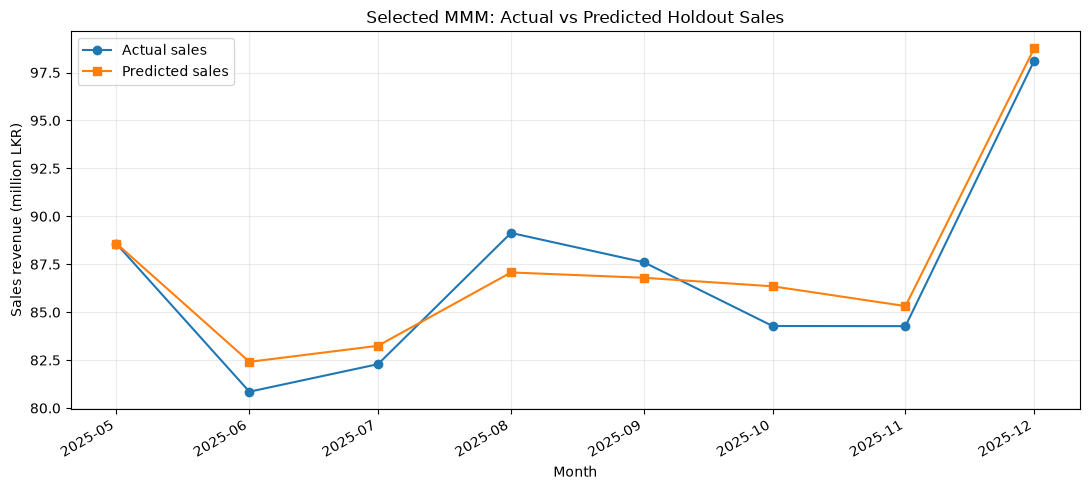

,model,train_r2,test_r2,test_mae_lkr,test_rmse_lkr,cv_rmse_lkr_mean,selected_by_cv
0,saturated_ridge_regression,0.837,0.932,1145613.245,1325303.972,3660068.004,True
1,ridge_regression,0.827,0.884,1592005.120,1729419.896,3825470.816,False
2,saturated_multiple_linear_regression,0.916,-2.172,7361841.189,9025368.289,7802946.969,False
3,multiple_linear_regression,0.901,-1.131,6316696.841,7397996.571,9285440.006,False


Selected by time-series CV: saturated_ridge_regression
Generated: final model, evaluation CSV, actual-vs-predicted PNG, residual PNG


In [4]:
comparison_path = OUTPUT/'model_comparison.csv'
if not comparison_path.exists():
    raise FileNotFoundError('Member 2 must first supply outputs/mmm/model_comparison.csv')
comparison = pd.read_csv(comparison_path)
if set(comparison['model']) != set(CANDIDATES):
    raise ValueError('The comparison file and supplied candidate model names do not match.')
if comparison['cv_rmse_lkr_mean'].isna().any():
    raise ValueError('Missing CV RMSE; cannot select model without validation evidence.')
selected_name = str(comparison.sort_values('cv_rmse_lkr_mean').iloc[0]['model'])
rows = []
holdout_by_model = {}
comparison_by_name = comparison.set_index('model')
for name, bundle in bundles.items():
    if bundle.get('training_end_month') != train.month.iloc[-1].strftime('%Y-%m-%d'):
        raise ValueError(f'{name} was not trained on the expected training period')
    train_preds = _predict_bundle(bundle, train)
    test_preds = _predict_bundle(bundle, test)
    tr, te = score(train[TARGET], train_preds), score(test[TARGET], test_preds)
    prior = comparison_by_name.loc[name]
    for prefix, metrics in [('train',tr),('test',te)]:
        for key in ('r2','mae_lkr','rmse_lkr'):
            if not np.isclose(metrics[key], prior[f'{prefix}_{key}'], rtol=1e-7, atol=1e-5):
                raise AssertionError(f'{name}: discrepancy from Member 2 for {prefix}_{key}')
    rows.append({
        'model': name, 'feature_variant': bundle['feature_variant'],
        'train_months': len(train), 'test_months': len(test),
        'train_start': train.month.iloc[0].strftime('%Y-%m-%d'),
        'train_end': train.month.iloc[-1].strftime('%Y-%m-%d'),
        'test_start': test.month.iloc[0].strftime('%Y-%m-%d'),
        'test_end': test.month.iloc[-1].strftime('%Y-%m-%d'),
        'train_r2': tr['r2'], 'train_mae_lkr': tr['mae_lkr'], 'train_rmse_lkr': tr['rmse_lkr'],
        'test_r2': te['r2'], 'test_mae_lkr': te['mae_lkr'], 'test_rmse_lkr': te['rmse_lkr'],
        'generalization_rmse_gap_lkr': te['rmse_lkr']-tr['rmse_lkr'],
        'cv_r2_mean': float(prior['cv_r2_mean']),
        'cv_rmse_lkr_mean': float(prior['cv_rmse_lkr_mean']),
        'cv_rmse_lkr_std': float(prior['cv_rmse_lkr_std']),
        'selected_by_cv': name == selected_name,
    })
    holdout_by_model[name] = np.asarray(test_preds, dtype=float)
evaluation = pd.DataFrame(rows).sort_values('cv_rmse_lkr_mean').reset_index(drop=True)
evaluation.to_csv(OUTPUT/'model_evaluation.csv', index=False)

winning_bundle = dict(bundles[selected_name])
winning_bundle['evaluation_method'] = 'Expanding-window CV selection, final 8-month chronological holdout evaluation'
winning_bundle['adstock_decay_rates'] = dict(zip(SPEND_CHANNELS, (0.6, 0.3, 0.2, 0.4, 0.4, 0.5)))
winning_bundle['previous_adstock_reference_month'] = df.month.iloc[-1].strftime('%Y-%m-%d')
winning_bundle['previous_adstock_reference'] = {key: float(df[key].iloc[-1]) for key in ADSTOCK_CHANNELS}
winning_bundle['external_factors_reference'] = {
    key: float(df[key].iloc[-1]) for key in winning_bundle['feature_columns']
    if key not in ADSTOCK_CHANNELS and not key.endswith('_saturated')
}
joblib.dump(winning_bundle, PROJECT_ROOT/'models/mmm_model.joblib')

actual = test[TARGET].to_numpy(dtype=float)
predicted = holdout_by_model[selected_name]
residual = actual - predicted
fig, ax = plt.subplots(figsize=(11,5))
ax.plot(test.month, actual/1e6, 'o-', label='Actual sales')
ax.plot(test.month, predicted/1e6, 's-', label='Predicted sales')
ax.set(title='Selected MMM: Actual vs Predicted Holdout Sales', xlabel='Month', ylabel='Sales revenue (million LKR)')
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(OUTPUT/'actual_vs_predicted.png', dpi=180)
plt.show(); plt.close(fig)
holdout_predictions = pd.DataFrame({'month':test.month.dt.strftime('%Y-%m-%d'),
                                     'actual_sales_lkr':actual,
                                     'predicted_sales_lkr':predicted,
                                     'residual_lkr':residual})
display(evaluation[['model','train_r2','test_r2','test_mae_lkr','test_rmse_lkr',
                    'cv_rmse_lkr_mean','selected_by_cv']].round(3))
print('Selected by time-series CV:', selected_name)
print('Generated: final model, evaluation CSV, actual-vs-predicted PNG, residual PNG')

## 4. Additional expanding-window rolling-origin backtest (training period only)

This is an **independent robustness check**, not a replacement for Member 2’s three-fold CV. Refit the **same Ridge(alpha=10) + StandardScaler** specification for eight one-month-ahead predictions entirely within the first 28 months (train sizes 20–27). Hill midpoint estimates are recalculated **only from each fold’s preceding training months**, so the fold being predicted does not influence its feature transformations. The May–December 2025 holdout remains unused here. The final saved estimator is **not overwritten** by these temporary models.

In [5]:
from sklearn.base import clone
from sklearn.metrics import r2_score
from src.saturation import apply_saturation

rolling_rows = []
rolling_predictions = []
# Dates here fall wholly within Member 2's 28-month training window.
for validation_index in range(20, len(train)):
    fold_train = train.iloc[:validation_index].copy()
    fold_valid = train.iloc[[validation_index]].copy()
    fold_midpoints = {channel: float(fold_train[channel].median()) for channel in ADSTOCK_CHANNELS}
    fold_train = apply_saturation(fold_train, half_saturation=fold_midpoints,
                                  slope=float(winning_bundle['saturation_slope']))
    fold_valid = apply_saturation(fold_valid, half_saturation=fold_midpoints,
                                  slope=float(winning_bundle['saturation_slope']))
    # Important: fitting the scaler and ridge on fold_train only avoids future leakage.
    fold_estimator = clone(winning_bundle['estimator'])
    columns = winning_bundle['feature_columns']
    fold_estimator.fit(fold_train.loc[:, columns], fold_train[TARGET])
    fold_pred = float(fold_estimator.predict(fold_valid.loc[:, columns])[0])
    actual_value = float(fold_valid[TARGET].iloc[0])
    rolling_predictions.append({'month': fold_valid.month.iloc[0].strftime('%Y-%m-%d'),
                                'actual_lkr': actual_value,
                                'predicted_lkr': fold_pred,
                                'residual_lkr': actual_value-fold_pred})
rolling = pd.DataFrame(rolling_predictions)
rolling_stats = score(rolling.actual_lkr, rolling.predicted_lkr)
print('Expanding 1-month-ahead backtest: train sizes 20..27; 8 validation months')
print('R²:', round(rolling_stats['r2'], 4), 'MAE (LKR):', round(rolling_stats['mae_lkr']),
      'RMSE (LKR):', round(rolling_stats['rmse_lkr']))
display(rolling)
assert len(rolling)==8 and rolling.month.max() <= train.month.max().strftime('%Y-%m-%d')
# Supplement the already-generated required CSV; no extra output files.
for key in ('r2','mae_lkr','rmse_lkr'):
    evaluation[f'rolling_8x1_{key}'] = np.nan
    evaluation.loc[evaluation.model==selected_name, f'rolling_8x1_{key}'] = rolling_stats[key]
evaluation.to_csv(OUTPUT/'model_evaluation.csv', index=False)


Expanding 1-month-ahead backtest: train sizes 20..27; 8 validation months
R²: 0.586 MAE (LKR): 2832744 RMSE (LKR): 4529052


,month,actual_lkr,predicted_lkr,residual_lkr
0,2024-09-01,88727078.0,7.674216e+07,1.198491e+07
1,2024-10-01,81505944.0,7.967315e+07,1.832795e+06
2,2024-11-01,76794912.0,7.837957e+07,-1.584656e+06
3,2024-12-01,97913978.0,9.849130e+07,-5.773205e+05
4,2025-01-01,82830118.0,8.131235e+07,1.517772e+06
5,2025-02-01,84819327.0,8.416428e+07,6.550496e+05
6,2025-03-01,81941885.0,8.502018e+07,-3.078294e+06
7,2025-04-01,96747407.0,9.531626e+07,1.431150e+06


## 5. Six-panel residual diagnostic (the required PNG)

The six panels provide errors vs fitted sales, time ordering, distribution, normal-quantile view, short-lag autocorrelation and absolute error by month. With **only eight holdout points**, these are descriptive diagnostics, not statistically reliable tests for normality or independent errors.

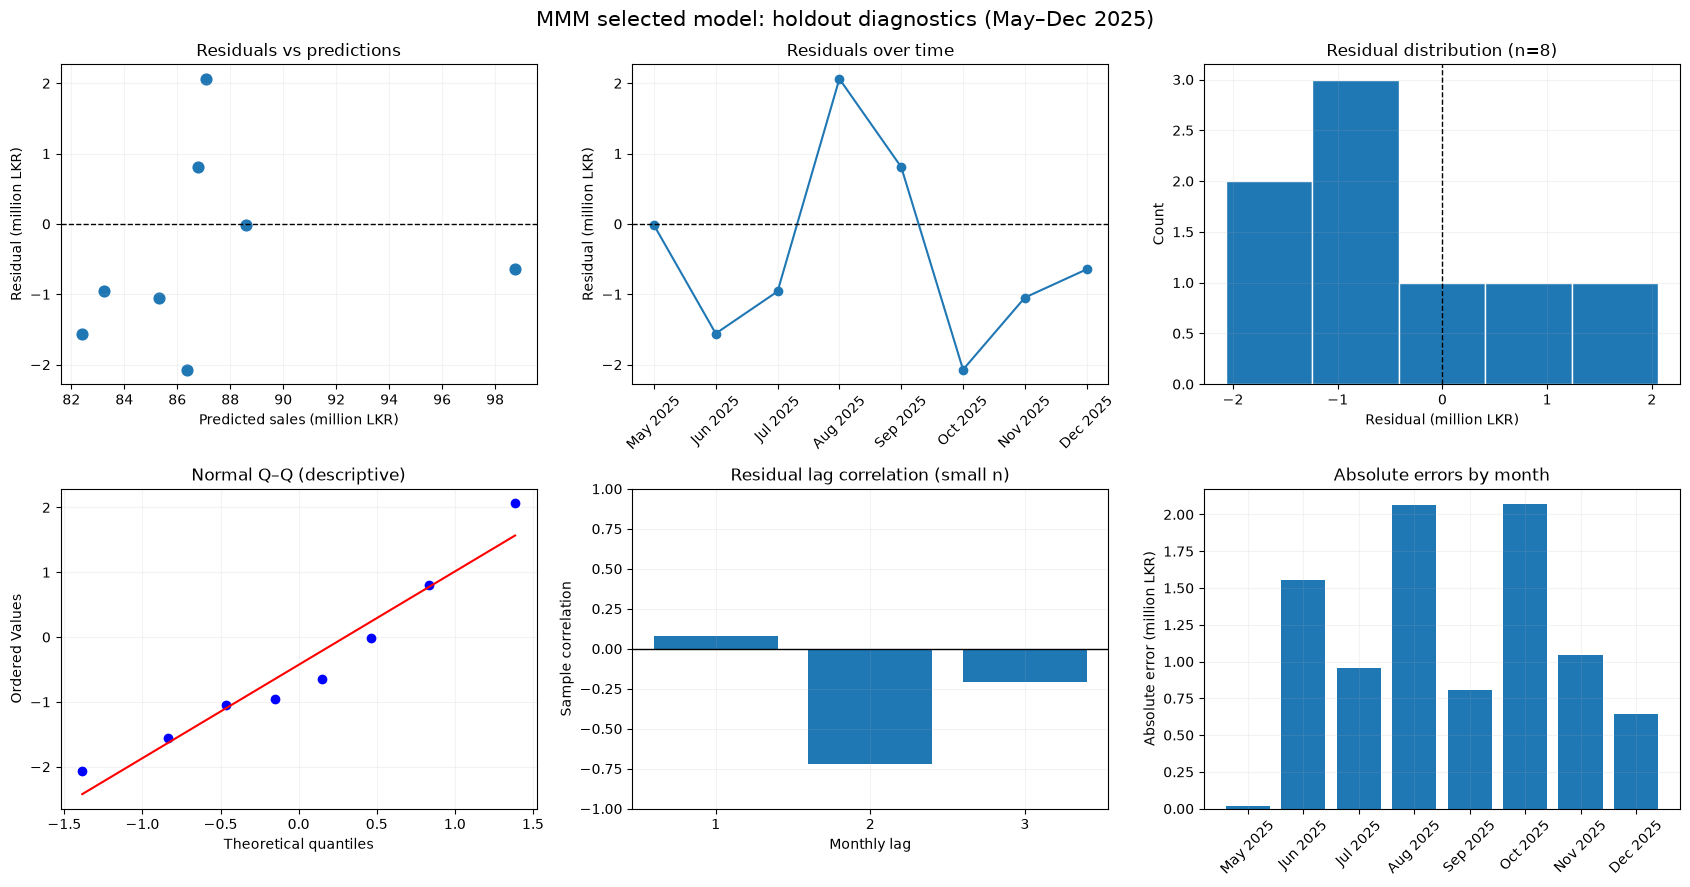

Residual mean (million LKR): -0.428 | Largest absolute residual (million LKR): 2.071


In [6]:
from scipy import stats
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
err_m = residual / 1e6
fitted_m = predicted / 1e6
actual_m = actual / 1e6
months = test.month.dt.strftime('%b %Y').tolist()
# 1 errors vs fitted
axs[0,0].scatter(fitted_m, err_m, s=60)
axs[0,0].axhline(0, color='black', linewidth=1, linestyle='--')
axs[0,0].set(xlabel='Predicted sales (million LKR)',ylabel='Residual (million LKR)',title='Residuals vs predictions')
# 2 error across holdout months
axs[0,1].plot(np.arange(len(err_m)), err_m, marker='o')
axs[0,1].axhline(0,color='black',linestyle='--',linewidth=1)
axs[0,1].set(xticks=range(len(months)),xticklabels=months,ylabel='Residual (million LKR)',title='Residuals over time')
axs[0,1].tick_params(axis='x',rotation=45)
# 3 distribution
axs[0,2].hist(err_m, bins=5, edgecolor='white')
axs[0,2].axvline(0,color='black',linestyle='--',linewidth=1)
axs[0,2].set(xlabel='Residual (million LKR)',ylabel='Count',title='Residual distribution (n=8)')
# 4 normal Q-Q; exploratory with n=8
stats.probplot(err_m, dist='norm', plot=axs[1,0])
axs[1,0].set_title('Normal Q–Q (descriptive)')
# 5 short lag sample ACF (not a significance test)
lag_values = np.arange(1,4)
lag_corrs = [np.corrcoef(err_m[:-lag],err_m[lag:])[0,1] for lag in lag_values]
axs[1,1].bar(lag_values,lag_corrs)
axs[1,1].axhline(0,color='black',linewidth=1)
axs[1,1].set(xticks=lag_values,ylim=(-1,1),xlabel='Monthly lag',ylabel='Sample correlation',title='Residual lag correlation (small n)')
# 6 absolute errors by holdout month
axs[1,2].bar(range(len(months)),np.abs(err_m))
axs[1,2].set(xticks=range(len(months)),xticklabels=months,ylabel='Absolute error (million LKR)',title='Absolute errors by month')
axs[1,2].tick_params(axis='x',rotation=45)
for axis in axs.flat:
    axis.grid(alpha=.15)
fig.suptitle('MMM selected model: holdout diagnostics (May–Dec 2025)',fontsize=15)
fig.tight_layout()
fig.savefig(OUTPUT/'residual_analysis.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)
print('Residual mean (million LKR):', round(float(np.mean(err_m)),3),
      '| Largest absolute residual (million LKR):', round(float(np.max(np.abs(err_m))),3))


## 6. Check training-vs-test generalisation
Large positive test minus train RMSE and negative holdout R² can indicate poor generalisation. A favourable gap alone does not prove a model is robust.

,model,train_r2,test_r2,train_rmse_lkr,test_rmse_lkr,generalization_rmse_gap_lkr
0,saturated_ridge_regression,0.837,0.932,3244753.531,1325303.972,-1919449.559
1,ridge_regression,0.827,0.884,3340286.809,1729419.896,-1610866.913
2,saturated_multiple_linear_regression,0.916,-2.172,2324552.854,9025368.289,6700815.435
3,multiple_linear_regression,0.901,-1.131,2522242.467,7397996.571,4875754.104


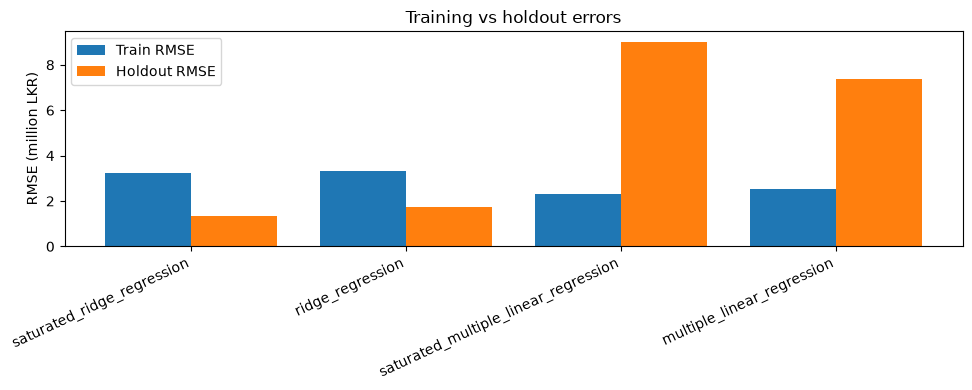

In [7]:
generalization = evaluation[['model','train_r2','test_r2','train_rmse_lkr','test_rmse_lkr',
                             'generalization_rmse_gap_lkr']].copy()
display(generalization.round(3))
fig,ax=plt.subplots(figsize=(10,4))
positions=np.arange(len(evaluation))
ax.bar(positions-.2,evaluation.train_rmse_lkr/1e6,width=.4,label='Train RMSE')
ax.bar(positions+.2,evaluation.test_rmse_lkr/1e6,width=.4,label='Holdout RMSE')
ax.set_xticks(positions, evaluation.model, rotation=25, ha='right')
ax.set_ylabel('RMSE (million LKR)'); ax.set_title('Training vs holdout errors')
ax.legend(); fig.tight_layout(); plt.show()

## 7. Actual vs predicted sales (holdout)

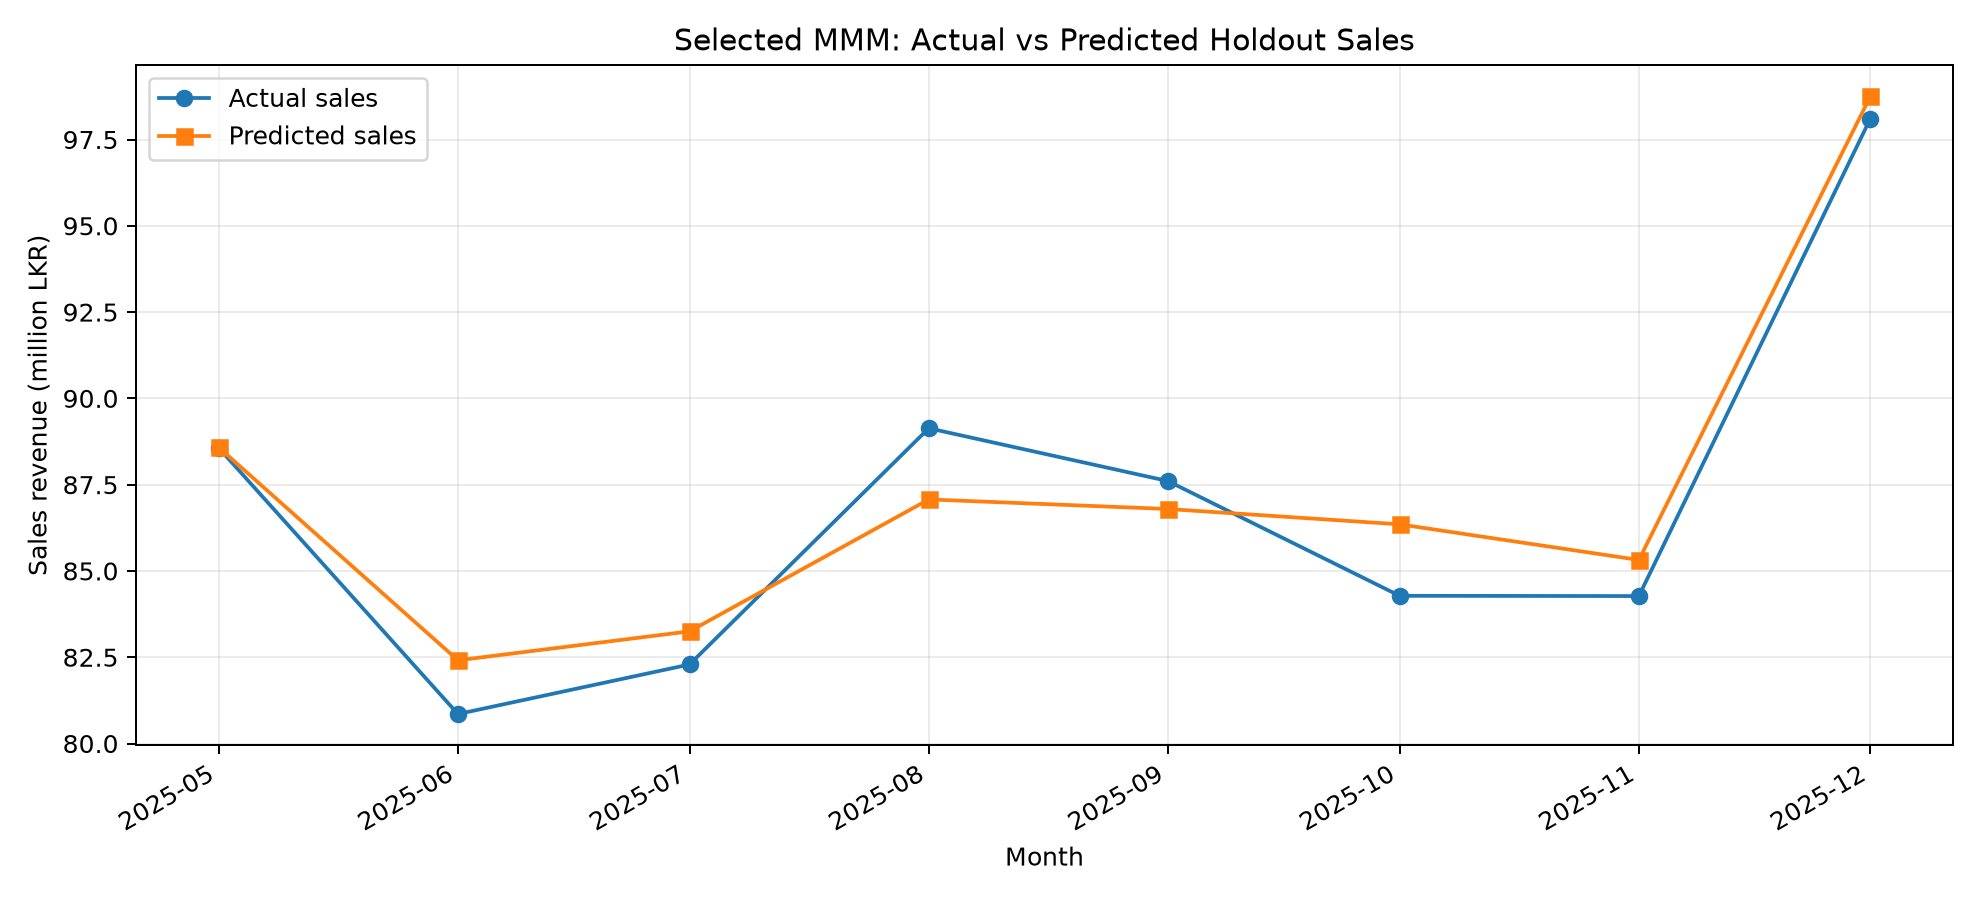

,month,actual_sales_lkr,predicted_sales_lkr,residual_lkr
28,2025-05-01,88565133.0,8.858043e+07,-1.529312e+04
29,2025-06-01,80854120.0,8.241168e+07,-1.557555e+06
30,2025-07-01,82290486.0,8.324981e+07,-9.593250e+05
31,2025-08-01,89134503.0,8.707247e+07,2.062031e+06
32,2025-09-01,87603596.0,8.679476e+07,8.088341e+05
33,2025-10-01,84280236.0,8.635103e+07,-2.070789e+06
34,2025-11-01,84272664.0,8.531908e+07,-1.046416e+06
35,2025-12-01,98107722.0,9.875238e+07,-6.446620e+05


In [8]:
display(Image(filename=str(OUTPUT/'actual_vs_predicted.png')))
display(holdout_predictions)

## 8. Residual analysis (actual − prediction)
Residuals show model errors. Only eight holdout observations are available, so statistical patterns are uncertain.

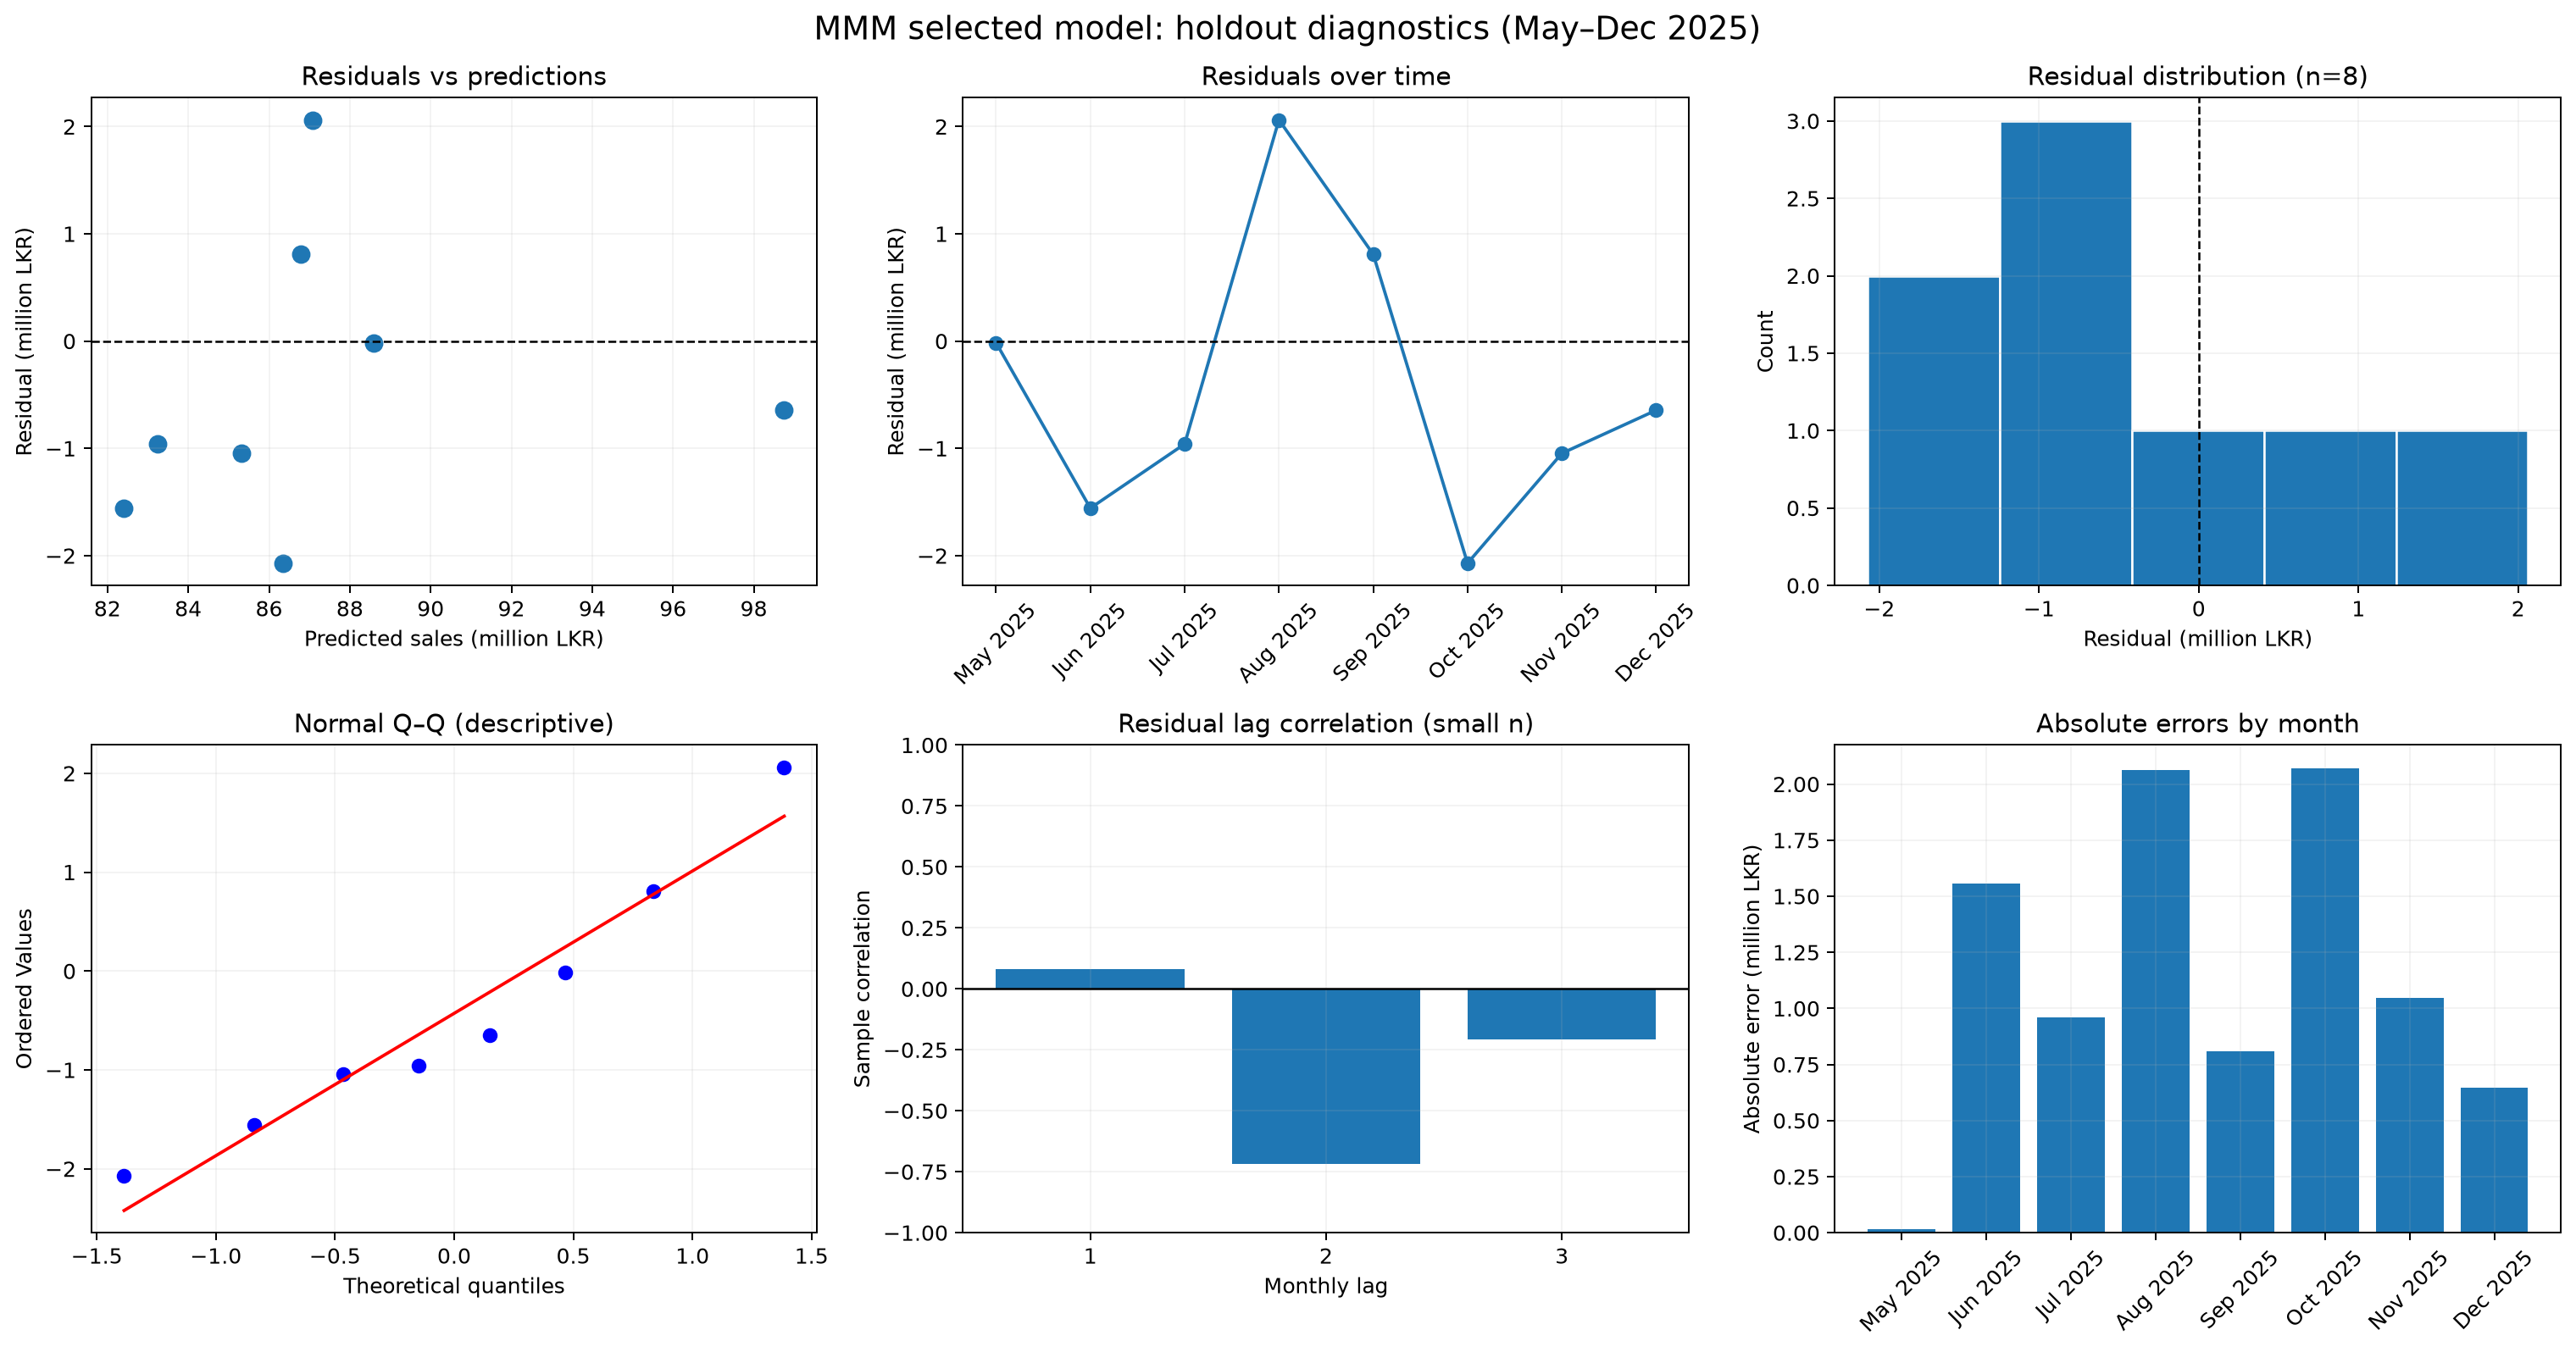

Mean holdout residual (LKR): -427897
Largest absolute error (LKR): 2070789


In [9]:
display(Image(filename=str(OUTPUT/'residual_analysis.png')))
print('Mean holdout residual (LKR):', round(holdout_predictions.residual_lkr.mean()))
print('Largest absolute error (LKR):', round(holdout_predictions.residual_lkr.abs().max()))

## 9. Reusable feature-based prediction API
`predict_sales` accepts Member 1's **adstock-adjusted data** (not raw monthly spend). It reproduces saved-model predictions.

In [10]:
feature_predictions = predict_sales(test, PROJECT_ROOT/'models/mmm_model.joblib')
assert np.allclose(feature_predictions.values, holdout_predictions.predicted_sales_lkr.values)
print('Feature-based test passed. First three forecasts (LKR):')
display(feature_predictions.head(3).to_frame())

Feature-based test passed. First three forecasts (LKR):


,predicted_sales_revenue_lkr
28,8.858043e+07
29,8.241168e+07
30,8.324981e+07


## 10. Budget allocation scenarios for Part 03
`predict_budget_allocation` accepts **raw LKR spend** for one month and converts it to adstock using the previous month's state. Explicit external factors and prior adstock are required. Below, all three allocations sum to the **same LKR 18 million**. As a demonstration, external factors and preceding carryover are held at the December 2025 snapshot; this is **not a validated future forecast or causal ROI estimate**.

In [11]:
model = load_model(PROJECT_ROOT/'models/mmm_model.joblib')
controls = model['external_factors_reference']
prior_adstock = model['previous_adstock_reference']
budget = 18_000_000
weights = {
 'equal_split': [1/6]*6,
 'tv_weighted': [.35,.13,.13,.13,.13,.13],
 'digital_weighted': [.10,.25,.25,.25,.075,.075]
}
results=[]
for name, fractions in weights.items():
    allocation=dict(zip(SPEND_CHANNELS, [budget*f for f in fractions]))
    forecast=predict_budget_allocation(allocation, controls, prior_adstock,
                                      PROJECT_ROOT/'models/mmm_model.joblib')
    results.append({'scenario':name, 'spend_lkr':sum(allocation.values()), 'predicted_revenue_lkr':forecast})
scenario_check=pd.DataFrame(results)
display(scenario_check)
assert np.allclose(scenario_check.spend_lkr, budget)
assert scenario_check.predicted_revenue_lkr.notna().all()

,scenario,spend_lkr,predicted_revenue_lkr
0,equal_split,18000000.0,9.500292e+07
1,tv_weighted,18000000.0,9.376988e+07
2,digital_weighted,18000000.0,9.848320e+07


## 11. Input validation and multi-month state propagation
Negative spend must fail. For multi-month simulations, call `next_adstock_state()` after each month and pass its result as the next period's `previous_adstock`. Do not reset adstock state each period.

In [12]:
equal = dict(zip(SPEND_CHANNELS, [budget/6]*6))
updated_state = next_adstock_state(equal, prior_adstock)
print('Updated state for next month:', updated_state)
try:
    invalid=equal.copy(); invalid['tv_spend_lkr'] = -1
    predict_budget_allocation(invalid, controls, prior_adstock,
                              PROJECT_ROOT/'models/mmm_model.joblib')
    raise AssertionError('Negative spend was unexpectedly accepted')
except ValueError as exc:
    print('PASS: invalid negative spend rejected:', exc)
# Example: next month reusing the propagated state; controls must be explicitly re-specified.
next_month_forecast = predict_budget_allocation(equal, controls, updated_state,
                                              PROJECT_ROOT/'models/mmm_model.joblib')
print('Second month hypothetical forecast using updated carryover:', round(next_month_forecast))

Updated state for next month: {'tv_adstock_lkr': 9796651.629247922, 'facebook_instagram_adstock_lkr': 5165389.1127867885, 'google_search_adstock_lkr': 4069776.717984644, 'youtube_adstock_lkr': 4898856.701410351, 'radio_adstock_lkr': 4340913.7866708785, 'outdoor_adstock_lkr': 6054417.348047212}
PASS: invalid negative spend rejected: Advertising spend and previous adstock cannot be negative
Second month hypothetical forecast using updated carryover: 93662132


## 12. Radio-spend sensitivity and scenario interpretation

Holding every other channel and control constant, inspect the model's **conditional** response to a small increase in radio spend. A negative response, if observed, is an associational model feature—not proof that radio advertising decreases sales. Scenario controls are fixed at **December 2025 peak-season levels**, so absolute projections are not typical-month forecasts.

In [13]:
radio_probe = dict(zip(SPEND_CHANNELS, [budget/6]*6))
base_forecast = predict_budget_allocation(radio_probe, controls, prior_adstock)
radio_probe['radio_spend_lkr'] += 100_000
radio_changed = predict_budget_allocation(radio_probe, controls, prior_adstock)
radio_sensitivity = radio_changed - base_forecast
print('Conditional predicted sales change with + LKR 100,000 radio spend:', round(radio_sensitivity, 2))
print('Radio negative conditional association:', radio_sensitivity < 0)
print('Note: all earlier scenario comparisons used a fixed total budget. This probe isolates one input.')


Conditional predicted sales change with + LKR 100,000 radio spend: -15220.89
Radio negative conditional association: True
Note: all earlier scenario comparisons used a fixed total budget. This probe isolates one input.


## 12. Findings and integration contract
- **Chosen model:** Hill-saturated Ridge using CV, not the final holdout for model selection.
- **Holdout:** eight consecutive months; quality is encouraging but validation sample is small.
- **Budget optimiser:** use raw spend API with explicit external controls and preceding adstock state, in **LKR**.
- **Not causal:** differences in model-predicted revenue are not demonstrated channel uplift, ROI, or profit. Do not deploy unconstrained optimisation based only on these numbers.
- **Artifacts:** see `reports/part02_mmm_findings.md`, `outputs/mmm/model_evaluation.csv`, diagnostics and `models/mmm_model.joblib`.

In [14]:
display(Markdown((PROJECT_ROOT/'reports/part02_mmm_findings.md').read_text(encoding='utf-8')[:1800]))
required = ['notebooks/02_mmm_model/03_model_evaluation.ipynb','models/mmm_model.joblib','src/predict_sales.py','outputs/mmm/model_evaluation.csv',
            'outputs/mmm/actual_vs_predicted.png','outputs/mmm/residual_analysis.png',
            'reports/part02_mmm_findings.md']
for path in required:
    assert (PROJECT_ROOT/path).is_file(), path
    print('PASS:', path)
# Exact equivalence: raw monthly spend + previous adstock equals feature-row forecast.
last, prev = df.iloc[-1], df.iloc[-2]
raw = {spend: float(last[stock] - winning_bundle['adstock_decay_rates'][spend]*prev[stock])
       for spend, stock in zip(SPEND_CHANNELS, ADSTOCK_CHANNELS)}
prior = {stock:float(prev[stock]) for stock in ADSTOCK_CHANNELS}
control = {key:float(last[key]) for key in winning_bundle['external_factors_reference']}
by_budget = predict_budget_allocation(raw, control, prior)
by_features = float(predict_sales(df.tail(1)).iloc[0])
assert np.isclose(by_budget, by_features, rtol=1e-10, atol=1e-5)
print('PASS: Raw-spend/adstock integration matches saved-model feature prediction')

# Part 02 — Marketing Mix Model Evaluation and Integration (Member 3)

## Dataset and methodology

- **36 monthly observations:** January 2023–December 2025; target: `sales_revenue_lkr`.
- **Six channels:** TV, Facebook/Instagram, Google Search, YouTube, Radio, Outdoor.
- **External controls:** price, promotions, competitor pressure, economic sentiment, exchange rate, inflation proxy, seasonal demand, holidays, and cyclic month indicators.
- **Chronological split:** 28 training months (January 2023–April 2025) and 8 holdout months (May–December 2025). **No shuffle.**
- Four candidate estimators and their fitting came from Member 2. **Member 3 reuses saved fitted estimators and independently verifies metrics** rather than fitting on the holdout.
- **Selection criterion:** Member 2's 3-fold expanding-window CV mean RMSE, not the holdout score; the separate holdout provides an out-of-sample check. Member 2's three CV folds have substantial score variability and use a small sample.

## Model comparison

| model                                | train_r2 | test_r2 | test_mae_lkr | test_rmse_lkr | cv_rmse_lkr_mean | selected_by_cv |
| :----------------------------------- | -------: | ------: | -----------: | ------------: | ---------------: | :------------- |
| saturated_ridge_regression           |    0.837 |   0.932 |  1145613.245 |   1325303.972 |      3660068.004 | True           |
| ridge_regression                     |    0.827 |   0.884 |  1592005.120 |   1729419.896 |      3825470.816 | False          |
| saturated_multiple_linear_regression |    0.916 |  -2.172 |  7361841.189 |   9025368.289 |      7802946.969 | False          |
| multiple_linear_regression           |    0.901 |  -1.131 |  6316696.841 |   7397996.571 |      9285440.006 | False          |

**Selected

PASS: notebooks/02_mmm_model/03_model_evaluation.ipynb
PASS: models/mmm_model.joblib
PASS: src/predict_sales.py
PASS: outputs/mmm/model_evaluation.csv
PASS: outputs/mmm/actual_vs_predicted.png
PASS: outputs/mmm/residual_analysis.png
PASS: reports/part02_mmm_findings.md
PASS: Raw-spend/adstock integration matches saved-model feature prediction
